<a href="https://colab.research.google.com/github/192424161Renee/Deep-Learning/blob/main/CSA4708_DEEP_LEARNING_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

print("Addition:", a + b)
print("Dot Product:", np.dot(a, b))

A = np.array([[1, 2], [3, 4]])
print("Matrix Addition:\n", A + A)
print("Transpose:\n", A.T)

Addition: [5 7 9]
Dot Product: 32
Matrix Addition:
 [[2 4]
 [6 8]]
Transpose:
 [[1 3]
 [2 4]]


In [ ]:
import numpy as np
import pandas as pd

data = np.array([[1, 2], [2, 4], [3, 6]])
print("Covariance:\n", np.cov(data.T))

A = np.array([[4, 2], [2, 3]])
values, vectors = np.linalg.eig(A)

print("Eigenvalues:", values)
print("Eigenvectors:\n", vectors)

Covariance:
 [[1. 2.]
 [2. 4.]]
Eigenvalues: [5.56155281 1.43844719]
Eigenvectors:
 [[ 0.78820544 -0.61541221]
 [ 0.61541221  0.78820544]]


In [ ]:
import numpy as np
from scipy.stats import binom

print("Probability:", binom.pmf(5, 10, 0.5))

p_d, p_pos_d, p_pos_nd = 0.01, 0.95, 0.05
p_pos = p_pos_d * p_d + p_pos_nd * (1 - p_d)

print("Bayes' Result:", (p_pos_d * p_d) / p_pos)

Probability: 0.24609375000000003
Bayes' Result: 0.16101694915254236


In [ ]:
import numpy as np
from scipy.stats import entropy

P = np.array([0.5, 0.5])
Q = np.array([0.8, 0.2])

print("Entropy:", entropy(P, base=2))
print("Cross-Entropy:", -np.sum(P * np.log2(Q)))
print("KL Divergence:", entropy(P, Q, base=2))

Entropy: 1.0
Cross-Entropy: 1.3219280948873622
KL Divergence: 0.32192809488736235


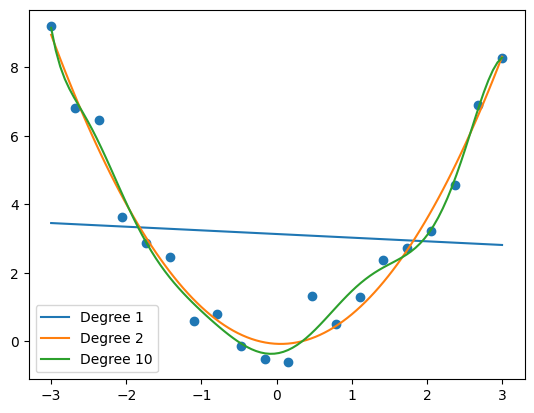

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

X = np.linspace(-3, 3, 20).reshape(-1, 1)
y = X.ravel()**2 + np.random.randn(20) * 0.5
X_test = np.linspace(-3, 3, 100).reshape(-1, 1)

for d in [1, 2, 10]:
    model = make_pipeline(PolynomialFeatures(d), LinearRegression())
    model.fit(X, y)
    plt.plot(X_test, model.predict(X_test), label=f"Degree {d}")

plt.scatter(X, y)
plt.legend()
plt.show()

In [ ]:
import tensorflow as tf

for opt in [tf.keras.optimizers.SGD(), tf.keras.optimizers.SGD(momentum=0.9), tf.keras.optimizers.Adam()]:
    w = tf.Variable(0.0)
    for i in range(100):
        with tf.GradientTape() as tape:
            loss = (w - 5)**2
        opt.apply_gradients([(tape.gradient(loss, w), w)])
    print(type(opt).__name__, "Weight:", round(w.numpy(), 3))

SGD Weight: 4.337
SGD Weight: 4.979
Adam Weight: 0.1


In [ ]:
import numpy as np

x = np.array([1, 0])
w = np.array([0.5, 0.3])
y = np.dot(x, w) + 0.2

print("Weighted Sum:", y)
print("Output:", int(y >= 0.5))

Weighted Sum: 0.7
Output: 1


In [ ]:
import numpy as np

X = np.array([[1, 0]])
Y = np.array([[1]])
W1 = np.random.rand(2, 3)
W2 = np.random.rand(3, 1)
sig = lambda x: 1 / (1 + np.exp(-x))

H = sig(X @ W1)
O = sig(H @ W2)
dO = (O - Y) * O * (1 - O)
dH = (dO @ W2.T) * H * (1 - H)

W2 -= 0.1 * H.T @ dO
W1 -= 0.1 * X.T @ dH

print("Output:", O)
print("Updated Weights:", W1, W2)

Output: [[0.62363618]]
Updated Weights: [[0.70258047 0.77941596 0.07765134]
 [0.49651457 0.05047638 0.05354188]] [[0.08359903]
 [0.07855796]
 [0.78179781]]


In [ ]:
from sklearn.datasets import load_iris
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = MLPClassifier(hidden_layer_sizes=(10,), max_iter=2000,
                      random_state=42)
model.fit(X_train, y_train)

print("Accuracy:", model.score(X_test, y_test))

Accuracy: 0.9666666666666667


In [ ]:
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
y_train = tf.keras.utils.to_categorical(y_train, 3)
y_test = tf.keras.utils.to_categorical(y_test, 3)

for name in ["L2", "Dropout", "Early Stopping"]:
    model = Sequential()
    reg = l2(0.01) if name == "L2" else None
    model.add(Dense(16, activation="relu", input_shape=(4,),
                    kernel_regularizer=reg))
    if name == "Dropout":
        model.add(Dropout(0.3))
    model.add(Dense(3, activation="softmax"))
    model.compile(optimizer="adam", loss="categorical_crossentropy",
                  metrics=["accuracy"])
    cb = [EarlyStopping(patience=3, restore_best_weights=True)] if name == "Early Stopping" else []
    model.fit(X_train, y_train, epochs=30, verbose=0, callbacks=cb)
    print(name, "Accuracy:", round(model.evaluate(X_test, y_test, verbose=0)[1], 3))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


L2 Accuracy: 0.7
Dropout Accuracy: 0.367


/usr/local/lib/python3.13/dist-packages/keras/src/callbacks/early_stopping.py:99: UserWarning: Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: accuracy,loss
  current = self.get_monitor_value(logs)


Early Stopping Accuracy: 0.333
